# [01] 전처리 · 머신러닝 · 성능평가 — EOL 최종검사 불량 선별 **(수정본)**

K-뉴딜 아카데미 스마트팩토리 캡스톤 · 공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터)

- 공통 데이터 파악
- 시각화
- 머신러닝 모델 구현

> **이 노트북은 1회차 배포본의 다음 6가지를 고친 수정본입니다.**
>
> | # | 고친 내용 | 왜 |
> |---|---|---|
> | ① | 모델에 `class_weight="balanced"` 추가 | 불량이 4%뿐이라 모델이 "전부 합격"이라고 답해 **불량을 한 건도 못 잡던** 문제 |
> | ② | `inspection_time_sec` 입력에서 제거 | 검사 후에 생기는 값 = **데이터 누출** |
> | ③ | 스케일링을 **학습/평가 분리 이후**로 이동 | 전체 데이터로 먼저 스케일링하면 평가 정보가 학습에 샌다 |
> | ④ | `random_state` 고정 | 실행할 때마다 결과가 달라지던 문제 |
> | ⑤ | 상위 5개 변수 재학습 시 **변수명 분리** | `X_train` 을 덮어써서 앞 셀 결과가 바뀌던 문제 |
> | ⑥ | `sns.barplot` 에 `hue` 지정 | 최신 seaborn 경고 제거 |
>
> 맨 뒤에 **개선 효과 확인** 섹션(수정 전후 비교 · 임계값 조정 · 규칙과 비교)을 덧붙였습니다.

---

## 1. 준비 — 라이브러리와 한글 폰트

| 도구 | 역할 |
|---|---|
| `pandas` (pd) | 표 데이터 처리 (엑셀에 해당) |
| `numpy` (np) | 숫자 계산 |
| `matplotlib` (plt) · `seaborn` (sns) | 그래프 |
| `scikit-learn` | 머신러닝 |

아래 셀은 **한 번만** 실행하면 됩니다.

한글 폰트를 설치하는 중입니다... (20초 정도 걸립니다)
준비 완료 | pandas 2.2.3 | Colab: True
한글 폰트 : NanumGothic


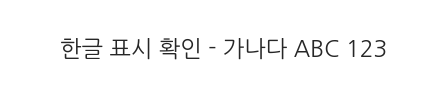

위 그림의 글자가 □□□ 로 보이면 [런타임 > 런타임 다시 시작] 후 이 셀을 다시 실행하세요.


In [1]:
# [준비 셀] 내용을 자세히 이해할 필요는 없습니다. 실행만 하세요.
# 라이브러리 불러오기 + 한글 폰트 설정
import os, sys, glob, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

sns.set_style("whitegrid")                      # ① 스타일 먼저

from matplotlib import font_manager as fm

KOREAN_FONTS = ["NanumGothic", "NanumBarunGothic", "Malgun Gothic", "AppleGothic",
                "Apple SD Gothic Neo", "Noto Sans CJK KR", "Noto Sans KR"]


def find_korean_font():
    """설치된 한글 폰트를 찾고, 없으면 Colab에서 나눔폰트를 설치한다."""
    have = {f.name for f in fm.fontManager.ttflist}
    for n in KOREAN_FONTS:
        if n in have:
            return n
    if IN_COLAB:                                 # 나눔폰트 설치 후 다시 찾기
        print("한글 폰트를 설치하는 중입니다... (20초 정도 걸립니다)")
        os.system("apt-get install -y fonts-nanum > /dev/null 2>&1")
        os.system(f"{sys.executable} -m pip install -q koreanize-matplotlib")
        for path in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):
            fm.fontManager.addfont(path)
        have = {f.name for f in fm.fontManager.ttflist}
        for n in KOREAN_FONTS:
            if n in have:
                return n
    return None


FONT = find_korean_font()                        # ② 폰트 나중에
if FONT:
    plt.rcParams["font.family"] = FONT
    plt.rcParams["font.sans-serif"] = [FONT] + list(plt.rcParams["font.sans-serif"])
plt.rcParams["axes.unicode_minus"] = False       # 음수 기호(-) 깨짐 방지
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("준비 완료 | pandas", pd.__version__, "| Colab:", IN_COLAB)
print("한글 폰트 :", FONT if FONT else "찾지 못함")

# ③ 자가진단 - 아래 그림에 한글이 보이면 정상입니다
plt.figure(figsize=(5, 0.9))
plt.text(0.5, 0.5, "한글 표시 확인 - 가나다 ABC 123",
         ha="center", va="center", fontsize=15)
plt.axis("off")
plt.show()
print("위 그림의 글자가 □□□ 로 보이면 [런타임 > 런타임 다시 시작] 후 이 셀을 다시 실행하세요.")

---

## 2. 데이터 불러오기

Colab은 구글의 임시 컴퓨터에서 돌아가므로 **데이터 파일을 올려 줘야** 합니다.
아래 셀이 흔한 경로를 먼저 찾아보고, 못 찾으면 **업로드 창**을 띄웁니다.
(드라이브를 쓰려면 맨 위 2줄의 `#` 을 지우세요.)

- 사용할 파일: `K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx`

In [2]:
# [데이터 적재 셀] 파일을 찾아서 읽어 오는 코드입니다. 실행만 하세요.
# from google.colab import drive
# drive.mount('/content/drive')

DATA_FILE = "K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx"
SEARCH_DIRS = [os.environ.get("KNEWDEAL_DATA_DIR", ""), ".", "..", "../..", "/content",
               "/content/drive/MyDrive", "/content/drive/MyDrive/K뉴딜"]

DATA_PATH = None
for d in SEARCH_DIRS:                      # ① 정확한 파일명으로 찾기
    if d and os.path.exists(os.path.join(d, DATA_FILE)):
        DATA_PATH = os.path.join(d, DATA_FILE)
        break
if DATA_PATH is None:                      # ② 키워드로 찾기
    for d in SEARCH_DIRS:
        hits = glob.glob(os.path.join(d, "*MiniCase*")) if d else []
        if hits:
            DATA_PATH = sorted(hits)[0]
            break
if DATA_PATH is None and IN_COLAB:         # ③ 직접 업로드
    from google.colab import files
    DATA_PATH = list(files.upload().keys())[0]

print("데이터 경로:", DATA_PATH)
df_raw = pd.read_excel(DATA_PATH, sheet_name="MiniCase_Data")
print("크기(행, 열):", df_raw.shape)
df_raw.head(3)

Saving K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정 (1).xlsx to K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정 (1).xlsx
데이터 경로: K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정 (1).xlsx
크기(행, 열): (1200, 20)


,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격


In [3]:
# 결측치 갯수 찾기
df_raw.isnull().sum()

,0
record_id,0
timestamp,0
shift,0
line_id,0
product_model,0
equipment_id,0
operator_group,0
torque_nm,12
pressure_bar,0
cycle_time_sec,0


In [4]:
# 토크 결측 복원에 쓸 '센서로그' 시트도 함께 읽는다
sensor_log = pd.read_excel(DATA_PATH, sheet_name="센서로그")
print("센서로그:", sensor_log.shape)
sensor_log

센서로그: (12, 4)


,record_id,timestamp,torque_nm_restored,근거
0,R00845,2026-07-08 15:37:46,30.650,교육용 합성 센서로그: 정상범위 복원 실습
1,R00268,2026-07-20 09:45:48,31.590,교육용 합성 센서로그: 정상범위 복원 실습
2,R00351,2026-07-10 10:38:06,32.010,교육용 합성 센서로그: 정상범위 복원 실습
3,R00740,2026-07-27 10:47:47,31.040,교육용 합성 센서로그: 정상범위 복원 실습
4,R00655,2026-07-04 14:11:22,30.450,교육용 합성 센서로그: 정상범위 복원 실습
5,R00472,2026-07-07 14:01:46,29.200,교육용 합성 센서로그: 정상범위 복원 실습
6,R00892,2026-07-24 08:02:46,31.960,교육용 합성 센서로그: 정상범위 복원 실습
7,R00196,2026-07-10 13:02:22,30.880,교육용 합성 센서로그: 정상범위 복원 실습
8,R00349,2026-07-08 13:32:59,31.760,교육용 합성 센서로그: 정상범위 복원 실습
9,R00290,2026-07-11 14:47:03,30.650,교육용 합성 센서로그: 정상범위 복원 실습


---

## 3. 데이터 정제

### 이 데이터의 정제 규칙 (1편 결과로 확정)

| 항목 | 처리 | 이유 |
|---|---|---|
| `torque_nm` 결측 12건 | **센서로그에서 복원** | 원본 로그가 있으면 추정보다 항상 낫다 |
| `vibration_mm_s` 결측 18건 | **설비별 중앙값**으로 채움 | 설비마다 진동 수준이 다르다 |
| `defect_type` 결측 1,152건 | **그대로 둠** | 합격품은 불량유형이 없다(구조적 결측) |



In [5]:
def clean_data(d, sensor_log):
    """꼭 필요한 정제만 수행한다."""
    d = d.copy()

    # ① 토크 결측 → 센서로그의 복원값으로 채운다 (record_id로 연결)
    restore = sensor_log.set_index("record_id")["torque_nm_restored"]
    d["torque_nm"] = d["torque_nm"].fillna(d["record_id"].map(restore))

    # ② 진동 결측 → 같은 설비의 중앙값으로 채운다
    d["vibration_mm_s"] = d["vibration_mm_s"].fillna(
        d.groupby("equipment_id")["vibration_mm_s"].transform("median"))

    # ③ defect_type(불량유형)은 구조적 결측이므로 그대로 둔다
    return d


df = clean_data(df_raw, sensor_log)
print("정제 후 남은 결측:")
print(df.isna().sum()[lambda s: s > 0].to_string())

정제 후 남은 결측:
defect_type    1152


---

## 4. 입력변수 고르기 — 데이터 누출 막기

**데이터 누출(data leakage)**: 예측 시점에는 알 수 없는 값을 모델에 넣는 것.
시험 문제지 뒤에 답이 인쇄된 상태로 공부하는 것과 같습니다.
**연습은 100점, 실전은 0점**이 됩니다.

### 의심스러운  변수 (검사 후에 생기는 값)

| 변수 | 이유 |
|---|---|
| `defect_type` | 불량유형. 불합격 판정이 난 뒤에 기록된다. 값이 있으면 그 제품은 이미 불합격이다 |
| `inspection_time_sec` | 검사 소요시간. 검사를 해야 생기는 값이다 |
| `rework_flag` | 재작업 여부. 불합격 이후의 조치다 |
| `rework_time_min` | 재작업시간. 불합격 이후의 조치다 |
| `final_disposition` | 최종처분(합격/재작업후합격). 사실상 정답의 복사본이다 |


> 성능이 비현실적으로 높으면(정확도 99%, AUC 0.99) **먼저 누출을 의심하세요.**
> 실무에서 가장 흔한 실패 원인입니다.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   record_id            1200 non-null   object        
 1   timestamp            1200 non-null   datetime64[ns]
 2   shift                1200 non-null   object        
 3   line_id              1200 non-null   object        
 4   product_model        1200 non-null   object        
 5   equipment_id         1200 non-null   object        
 6   operator_group       1200 non-null   object        
 7   torque_nm            1200 non-null   float64       
 8   pressure_bar         1200 non-null   float64       
 9   cycle_time_sec       1200 non-null   float64       
 10  temperature_c        1200 non-null   float64       
 11  vibration_mm_s       1200 non-null   float64       
 12  downtime_min         1200 non-null   int64         
 13  energy_kwh           1200 non-nul

In [ ]:
# 목적변수 선택 및 인코딩, label

참고:

In [7]:
# 수치형(연속형) 변수: float, int 타입을 가진 열 선택
numeric_features_auto = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 범주형 변수: object(문자열) 또는 category 타입을 가진 열 선택
categorical_features_auto = df.select_dtypes(include=['object', 'category']).columns.tolist()

# 데이터 누출(leakage) 방지를 위해 제외해야 할 ID 및 목적변수 등은 리스트에서 직접 제외할 수 있습니다
exclude_cols = ['record_id', 'inspection_result', 'defect_type', 'final_disposition']

numeric_features_auto = [col for col in numeric_features_auto if col not in exclude_cols]
categorical_features_auto = [col for col in categorical_features_auto if col not in exclude_cols]

print("자동 분류된 수치형 변수:", numeric_features_auto)
print("자동 분류된 범주형 변수:", categorical_features_auto)

자동 분류된 수치형 변수: ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min', 'energy_kwh', 'inspection_time_sec', 'rework_time_min']
자동 분류된 범주형 변수: ['shift', 'line_id', 'product_model', 'equipment_id', 'operator_group', 'rework_flag']


In [8]:
df['inspection_result'][:6]

,inspection_result
0,합격
1,합격
2,합격
3,합격
4,합격
5,합격


In [9]:
df['inspection_result'] = df['inspection_result'].map({'합격': 0, '불합격': 1})
display(df['inspection_result'][:3])

,inspection_result
0,0
1,0
2,0


In [11]:
y = df['inspection_result']
y

,inspection_result
0,0
1,0
2,0
3,0
4,0
...,...
1195,0
1196,0
1197,0
1198,0


의심스러운 변수 (Data leakage)

In [12]:
df.final_disposition.value_counts()

,count
final_disposition,
합격,1152
재작업후합격,48


In [13]:
df[['rework_time_min', 'defect_type','rework_flag']][:3]

,rework_time_min,defect_type,rework_flag
0,0,NaN,N
1,0,NaN,N
2,0,NaN,N


In [14]:
df['defect_type'].value_counts()

,count
defect_type,
치수불량,13
체결불량,13
외관불량,13
작동불량,9


In [15]:
df['rework_flag'].value_counts()

,count
rework_flag,
N,1152
Y,48


<Axes: >

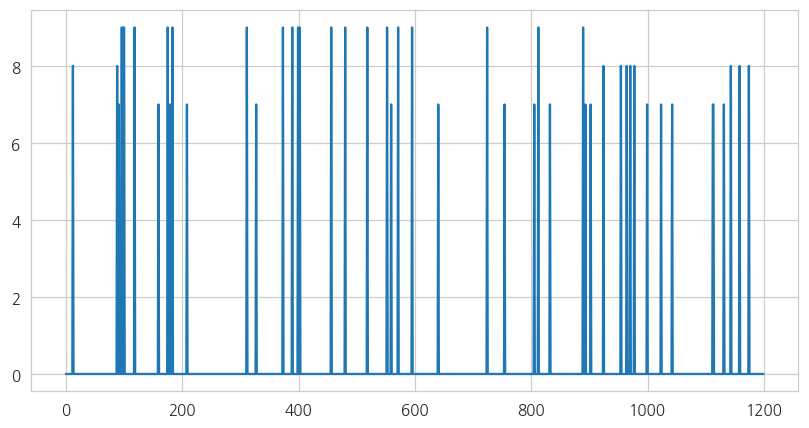

In [16]:
df['rework_time_min'].plot()

In [17]:
(df['rework_time_min'] > 0 ).sum()

np.int64(48)

연속형 변수 검사

<Axes: >

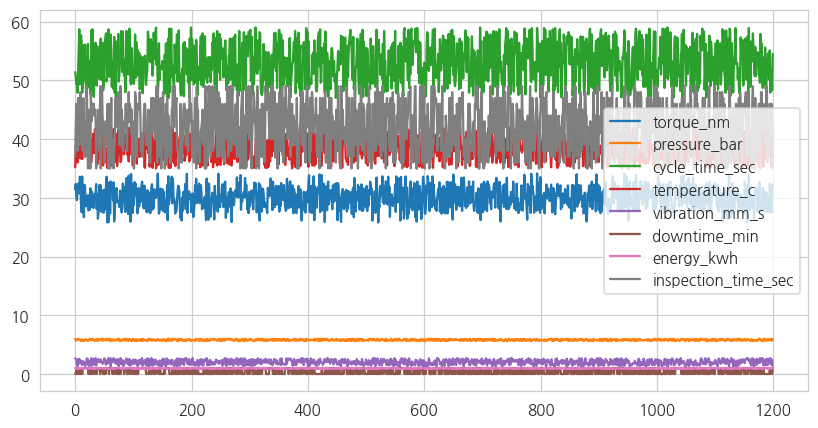

In [21]:
# [수정 ②] inspection_time_sec(검사 소요시간)은 '검사를 해야 생기는 값'이므로 제외한다.
#          검사 전에 불량을 예측하는 모델에 넣으면 데이터 누출이 된다.
numeric_features = ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c',
                    'vibration_mm_s', 'downtime_min', 'energy_kwh', 'inspection_time_sec']
df[numeric_features].plot()

<Axes: >

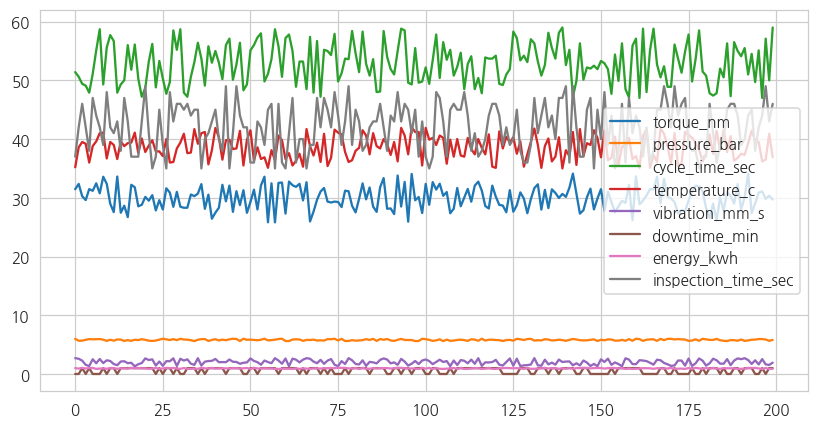

In [22]:
df[numeric_features][:200].plot()

In [23]:
# 범주형 변수
categorical_features = ['shift', 'line_id', 'product_model', 'equipment_id', 'operator_group']
df[categorical_features][:3]

,shift,line_id,product_model,equipment_id,operator_group
0,야간,L1,P1,M04,G01
1,주간,L2,P2,M04,G02
2,주간,L1,P1,M03,G03


In [24]:
for c in categorical_features:
    print(df[c].value_counts())

shift
주간    640
야간    560
Name: count, dtype: int64
line_id
L1    650
L2    550
Name: count, dtype: int64
product_model
P1    650
P2    550
Name: count, dtype: int64
equipment_id
M04    300
M03    300
M02    300
M01    300
Name: count, dtype: int64
operator_group
G01    200
G02    200
G03    200
G04    200
G05    200
G06    200
Name: count, dtype: int64


In [25]:
# features = df.columns.difference(['inspection_result', 'final_disposition','timestamp' ])
# X = df[features]



연속형 변수 스케일링

In [ ]:
# [수정 ③] 스케일러를 '만들기만' 한다.
#   전체 데이터로 fit_transform 하면 평가 데이터의 평균·표준편차까지 학습에 반영되어
#   데이터 누출이 된다. 실제 변환은 학습/평가를 나눈 뒤 아래 [분리] 셀에서 한다.
sc = StandardScaler()

In [26]:
# 스케일링 전 원본 값 (아직 변환하지 않았다)
df[numeric_features][:3]

,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_time_sec
0,31.460,5.980,51.400,35.200,2.700,0,1.000,37
1,32.370,5.660,50.600,38.600,2.590,0,0.915,42
2,30.260,5.680,49.400,39.500,2.270,1,1.044,46


In [ ]:
# 나중에 inference 시 새로운 데이터에 대해서는... sc.transform(X_new)

범주형 변수 원핫인코딩

In [27]:
pd.get_dummies(df[categorical_features])[:3]*1

,shift_야간,shift_주간,line_id_L1,line_id_L2,product_model_P1,product_model_P2,equipment_id_M01,equipment_id_M02,equipment_id_M03,equipment_id_M04,operator_group_G01,operator_group_G02,operator_group_G03,operator_group_G04,operator_group_G05,operator_group_G06
0,1,0,1,0,1,0,0,0,0,1,1,0,0,0,0,0
1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0
2,0,1,1,0,1,0,0,0,1,0,0,0,1,0,0,0


참고: 이진분류가 아니라 불량의 4 유형까지 나누는 5진 분류를 하는 코드 (현재는 데이터 수가 적어서 동작하지 않음)

In [29]:
# y2 (defect_type)의 결측치를 '정상'으로 채우고 범주별로 0~4 매핑
# 기존 고유값: NaN(정상), 치수불량, 체결불량, 외관불량, 작동불량

# 결측치는 '정상'으로 대체
y2_filled = df['defect_type'].fillna('정상')

# 각 불량 유형을 0, 1, 2, 3, 4로 매핑하는 딕셔너리 정의
defect_mapping = {
    '정상': 0,
    '치수불량': 1,
    '체결불량': 2,
    '외관불량': 3,
    '작동불량': 4
}

y2_mapped = y2_filled.map(defect_mapping)

print("--- 매핑 후 값 분포 ---")
print(y2_mapped.value_counts().sort_index())

# 커널의 y2 변수 업데이트
y2 = y2_mapped


--- 매핑 후 값 분포 ---
defect_type
0    1152
1      13
2      13
3      13
4       9
Name: count, dtype: int64


In [30]:
y2.value_counts()

,count
defect_type,
0,1152
1,13
2,13
3,13
4,9


X 준비

In [31]:
X_cat = pd.get_dummies(df[categorical_features])
X = pd.concat([df[numeric_features], X_cat], axis=1)
display(X.head(3))

,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_time_sec,shift_야간,shift_주간,line_id_L1,line_id_L2,product_model_P1,product_model_P2,equipment_id_M01,equipment_id_M02,equipment_id_M03,equipment_id_M04,operator_group_G01,operator_group_G02,operator_group_G03,operator_group_G04,operator_group_G05,operator_group_G06
0,31.460,5.980,51.400,35.200,2.700,0,1.000,37,True,False,True,False,True,False,False,False,False,True,True,False,False,False,False,False
1,32.370,5.660,50.600,38.600,2.590,0,0.915,42,False,True,False,True,False,True,False,False,False,True,False,True,False,False,False,False
2,30.260,5.680,49.400,39.500,2.270,1,1.044,46,False,True,True,False,True,False,False,False,True,False,False,False,True,False,False,False


In [ ]:
# [수정 ③] 먼저 나누고, 스케일링은 '학습 데이터에서만' 기준을 배운다
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=19, stratify=y)

X_train = X_train.copy()
X_test = X_test.copy()
X_train[numeric_features] = sc.fit_transform(X_train[numeric_features])  # 학습: 기준 학습 + 변환
X_test[numeric_features] = sc.transform(X_test[numeric_features])        # 평가: 변환만

print(f"학습 {len(X_train)}건 (불합격 {int(y_train.sum())}건) / "
      f"평가 {len(X_test)}건 (불합격 {int(y_test.sum())}건)")

In [ ]:
X_train[:3]

In [ ]:
from sklearn.metrics import classification_report

# [수정 ①] class_weight="balanced" : 불량(4%)을 틀렸을 때 벌점을 크게 준다.
#          이 옵션이 없으면 모델은 "전부 합격"이라고 답하는 것이 유리하다고 판단한다.
# [수정 ④] random_state 고정 : 실행할 때마다 결과가 달라지지 않게 한다.
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                              class_weight="balanced", random_state=42)
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                            class_weight="balanced", random_state=42)

In [ ]:
def run_model(model, X_tr=None, X_te=None, y_tr=None, y_te=None):
    """모델을 학습하고 혼동행렬과 분류 리포트를 출력한다."""
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    y_tr = y_train if y_tr is None else y_tr
    y_te = y_test if y_te is None else y_te
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    print(confusion_matrix(y_te, y_pred))
    print(classification_report(y_te, y_pred, zero_division=0))

In [ ]:
for m in [lr, tree, rf]:
  print(m)
  run_model(m)

In [ ]:
rf.feature_importances_

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 특성 이름과 중요도를 매핑하여 데이터프레임 생성
importances = rf.feature_importances_
features = X_train.columns

feature_imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 시각화  [수정 ⑥] hue 지정 (최신 seaborn 경고 제거)
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df,
            hue='Feature', palette='viridis', legend=False)
plt.title('Random Forest Feature Importances (Descending Order)')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:

# 과제: 입력변수를 현재 수치형 8개, 범주형 5개를 사용했는데 (총 13) 이를 줄여서 5개의 변수만
# 사용할 때, 2진분류 성능이 어떻게 달라지는지 확인하시오

In [ ]:
feature_imp_df

In [ ]:
# feature_imp_df에서 상위 5개 특성을 리스트로 추출
top_5_features = feature_imp_df['Feature'].head(5).tolist()
print("상위 5개 특성 리스트:", top_5_features)

In [ ]:
# [수정 ⑤] X_train/X_test 를 덮어쓰지 않도록 별도 이름을 쓴다.
#          (덮어쓰면 위쪽 셀을 다시 실행했을 때 결과가 뒤바뀐다)
X_5 = X[top_5_features]
X_train5, X_test5, y_train5, y_test5 = train_test_split(
    X_5, y, test_size=0.25, random_state=19, stratify=y)

num5 = [c for c in top_5_features if c in numeric_features]
sc5 = StandardScaler()
X_train5 = X_train5.copy()
X_test5 = X_test5.copy()
X_train5[num5] = sc5.fit_transform(X_train5[num5])
X_test5[num5] = sc5.transform(X_test5[num5])

# 모델도 새로 만들어서 위쪽 모델(rf 등)을 건드리지 않는다
lr5 = LogisticRegression(max_iter=2000, class_weight="balanced")
tree5 = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                               class_weight="balanced", random_state=42)
rf5 = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                             class_weight="balanced", random_state=42)

for m in [lr5, tree5, rf5]:
    print("=" * 50)
    print(f"[모델: {m.__class__.__name__} - 변수 5개 사용]")
    run_model(m, X_train5, X_test5, y_train5, y_test5)

---

## 개선 효과 확인 ① — `class_weight` 하나가 바꾸는 것

같은 데이터, 같은 모델인데 **옵션 하나**로 결과가 어떻게 달라지는지 직접 비교해 봅니다.

In [ ]:
from sklearn.metrics import roc_auc_score, recall_score, precision_score

rows = []
for tag, cw in [("수정 전 (class_weight 없음)", None), ("수정 후 (balanced)", "balanced")]:
    for name, m in [("로지스틱회귀", LogisticRegression(max_iter=2000, class_weight=cw)),
                    ("의사결정나무", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                            class_weight=cw, random_state=42)),
                    ("랜덤포레스트", RandomForestClassifier(n_estimators=300, max_depth=8,
                                                            min_samples_leaf=5, class_weight=cw,
                                                            random_state=42))]:
        m.fit(X_train, y_train)
        proba = m.predict_proba(X_test)[:, 1]
        pred = m.predict(X_test)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        rows.append({"구분": tag, "모델": name, "TP(잡음)": tp, "FN(놓침)": fn,
                     "FP(헛경보)": fp,
                     "Recall": round(recall_score(y_test, pred, zero_division=0), 3),
                     "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
                     "ROC_AUC": round(roc_auc_score(y_test, proba), 3)})

compare = pd.DataFrame(rows).set_index(["구분", "모델"])
display(compare)

print("수정 전에는 TP(잡아낸 불량)가 0 이다. 정확도는 96%지만 불량을 하나도 못 잡는 모델이다.")
print("ROC_AUC는 수정 전후가 비슷하다 → 모델의 '순위 매기는 능력'은 원래 있었고,")
print("0.5라는 칸막이(임계값)와 불균형 때문에 결과가 0으로 나왔던 것이다.")

---

## 개선 효과 확인 ② — 임계값 조정

모델은 0/1이 아니라 **확률**을 출력합니다. `predict()` 는 0.5를 기준으로 자르는데,
이 기준은 **운영 정책**이므로 현장 사정에 맞게 바꿀 수 있습니다.

- 임계값을 **낮추면** → 추가검사가 늘고, 놓치는 불량이 줄어든다 (Recall ↑, Precision ↓)
- 임계값을 **높이면** → 추가검사는 줄지만, 불량을 더 많이 놓친다

In [ ]:
best = tree          # ROC-AUC가 가장 높았던 모델 (위 표에서 확인)
best.fit(X_train, y_train)
proba = best.predict_proba(X_test)[:, 1]

rows = []
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"임계값": th, "추가검사 건수": int(pred.sum()), "TP(잡음)": tp,
                 "FN(놓침)": fn, "FP(헛경보)": fp,
                 "Recall": round(recall_score(y_test, pred, zero_division=0), 3),
                 "Precision": round(precision_score(y_test, pred, zero_division=0), 3)})
th_tbl = pd.DataFrame(rows)
display(th_tbl)

plt.figure(figsize=(7, 4))
plt.plot(th_tbl["임계값"], th_tbl["Recall"], "o-", label="Recall (놓치지 않는 비율)")
plt.plot(th_tbl["임계값"], th_tbl["Precision"], "s-", label="Precision (경보 적중률)")
plt.axvline(0.5, color="gray", ls="--", label="기본값 0.5")
plt.xlabel("임계값")
plt.title("임계값에 따른 맞바꿈(trade-off)")
plt.legend()
plt.show()

---

## 개선 효과 확인 ③ — 간단한 규칙과 비교하기

1~2회차에서 만든 **Baseline 규칙**과 머신러닝을 같은 기준(혼동행렬)으로 비교합니다.

| 버전 | 규칙 |
|---|---|
| **v0** | 체결토크 < 27 또는 > 33 |
| **v1** | v0 **또는** (야간조 AND M03) |

규칙은 전체 1,200건에 적용하고, 머신러닝은 평가용 300건에 적용했으므로
**건수가 아니라 비율(Recall·Precision)** 로 비교해야 공정합니다.

In [ ]:
# 주의: df['inspection_result'] 는 앞에서 0/1 로 바꿨으므로 y 와 같다
actual = y
v0 = ((df["torque_nm"] < 27) | (df["torque_nm"] > 33)).astype(int)
v1 = (v0 | ((df["shift"] == "야간") & (df["equipment_id"] == "M03"))).astype(int)

rows = []
for name, rule in [("규칙 v0 (토크 규격 이탈)", v0), ("규칙 v1 (토크 이탈 또는 야간M03)", v1)]:
    tn, fp, fn, tp = confusion_matrix(actual, rule, labels=[0, 1]).ravel()
    rows.append({"방법": name, "추가확인": int(rule.sum()), "TP": tp, "FN": fn, "FP": fp,
                 "Recall": round(tp / (tp + fn), 3),
                 "Precision": round(tp / (tp + fp), 3)})

# 머신러닝(의사결정나무, 임계값 0.3)
pred = (proba >= 0.3).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
rows.append({"방법": "머신러닝 (의사결정나무, 임계값 0.3)", "추가확인": int(pred.sum()),
             "TP": tp, "FN": fn, "FP": fp,
             "Recall": round(tp / (tp + fn), 3) if (tp + fn) else 0,
             "Precision": round(tp / (tp + fp), 3) if (tp + fp) else 0})

display(pd.DataFrame(rows).set_index("방법"))

---

## 정리 — 이 데이터에서 배울 것 5가지

| # | 내용 |
|---|---|
| 1 | **정확도 착시** — 불량이 4%면 "전부 합격"이라고만 해도 정확도 96%다. 반드시 Recall·Precision을 함께 본다 |
| 2 | **불균형 처리** — `class_weight="balanced"` 가 없으면 모델은 드문 쪽을 아예 포기한다 |
| 3 | **임계값은 운영 정책** — 모델을 바꾸지 않고도 "불량을 더 잡을지, 검사를 덜 할지" 조절할 수 있다 |
| 4 | **데이터 누출** — 검사 후에 생기는 변수(`inspection_time_sec`, `rework_flag`, `defect_type`, `final_disposition`)를 넣으면 성적은 좋아지지만 현장에서는 쓸 수 없다 |
| 5 | **간단한 규칙이 이길 수도 있다** — 머신러닝을 쓰는 것이 목적이 아니다. 이 데이터에서는 규칙 v1이 비슷하거나 더 나은 균형을 보인다 |

### 왜 성능이 더 오르지 않는가

이 데이터는 **일부러 그렇게 설계**되었습니다. 불합격 48건 중 **28건은 체결토크가 규격 안**에
있습니다. 주어진 변수만으로는 구분할 수 없는 불량이 절반이 넘는다는 뜻입니다.

따라서 다음 단계는 "더 좋은 모델 찾기"가 아니라 다음 두 가지입니다.

1. **새로운 변수 만들기** — 규격 이탈 여부, 야간·M03 조합 플래그 등 (Feature Engineering)
2. **새로운 데이터 요청하기** — 지금 센서로는 보이지 않는 불량이 있다는 근거를 제시